# Cinemood — تشخیص حال از روی چهره (هوش ۳)
یک CNN ساده روی دیتاست FER-2013 برای تشخیص ۵ حالت: angry, happy, neutral, sad, surprise.

## ۱) داده
فقط ۵ حالت انتخاب‌شده نگه داشته شدن (fear و disgust حذف شدن). تصاویر 48×48 خاکستری‌ان و بین ۰ تا ۱ نرمال شدن. تقسیم train/val/test همون Usage خود دیتاسته.

RAW emotion counts:
emotion
0    4953
1     547
2    5121
3    8989
4    6077
5    4002
6    6198
Name: count, dtype: int64
Usage
Training       28709
PublicTest      3589
PrivateTest     3589
Name: count, dtype: int64
train: (24176, 48, 48, 1) val: (3037, 48, 48, 1) test: (3006, 48, 48, 1)
angry 3995
happy 7215
neutral 4965
sad 4830
surprise 3171


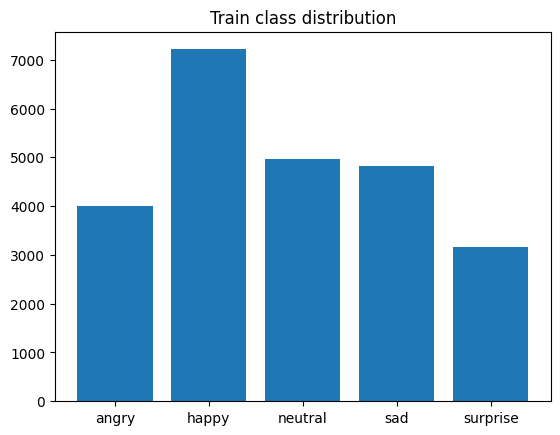

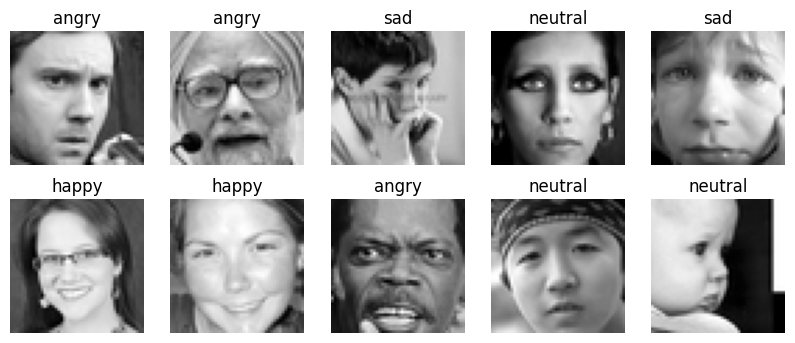

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("fer2013.csv")
print("RAW emotion counts:")
print(df["emotion"].value_counts().sort_index())
print(df["Usage"].value_counts())

MOODS = ["angry", "happy", "neutral", "sad", "surprise"]
# کد عددی دیتاست -> شماره حال ما
ID_MAP = {0: 0, 3: 1, 6: 2, 4: 3, 5: 4}

df = df[df["emotion"].isin(list(ID_MAP.keys()))].copy()
df["label"] = df["emotion"].map(ID_MAP).astype(int)

def to_images(frame):
    X = np.stack([np.array(p.split(), dtype="float32") for p in frame["pixels"]])
    X = X.reshape(-1, 48, 48, 1) / 255.0
    return X, frame["label"].values

X_train, y_train = to_images(df[df["Usage"] == "Training"])
X_val, y_val = to_images(df[df["Usage"] == "PublicTest"])
X_test, y_test = to_images(df[df["Usage"] == "PrivateTest"])

print("train:", X_train.shape, "val:", X_val.shape, "test:", X_test.shape)
for i, m in enumerate(MOODS):
    print(m, (y_train == i).sum())

plt.bar(MOODS, [(y_train == i).sum() for i in range(5)])
plt.title("Train class distribution")
plt.show()

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(MOODS[y_train[i]])
    plt.axis("off")
plt.show()

In [ ]:
from tensorflow.keras import layers, models, callbacks
from sklearn.utils.class_weight import compute_class_weight

EPOCHS = 30

w = compute_class_weight("balanced", classes=np.arange(5), y=y_train)
class_weight = dict(enumerate(w))

model = models.Sequential([
    layers.Input(shape=(48, 48, 1)),
    layers.RandomFlip("horizontal"),

    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(5, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

cbs = [
    callbacks.ModelCheckpoint("best_model.keras", save_best_only=True, monitor="val_accuracy"),
    callbacks.EarlyStopping(patience=6, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(factor=0.5, patience=3),
]

history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=128,
                    class_weight=class_weight, callbacks=cbs)

Epoch 1/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 190s 902ms/step - accuracy: 0.2417 - loss: 1.6410 - val_accuracy: 0.1999 - val_loss: 9.8822 - learning_rate: 0.0010
Epoch 2/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 218s 987ms/step - accuracy: 0.2656 - loss: 1.5224 - val_accuracy: 0.2091 - val_loss: 3.5034 - learning_rate: 0.0010
Epoch 3/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 186s 899ms/step - accuracy: 0.3165 - loss: 1.4591 - val_accuracy: 0.3510 - val_loss: 1.4600 - learning_rate: 0.0010
Epoch 4/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 198s 877ms/step - accuracy: 0.3329 - loss: 1.4193 - val_accuracy: 0.4827 - val_loss: 1.2725 - learning_rate: 0.0010
Epoch 5/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 183s 971ms/step - accuracy: 0.3812 - loss: 1.3614 - val_accuracy: 0.4837 - val_loss: 1.2726 - learning_rate: 0.0010
Epoch 6/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 183s 865ms/step - accuracy: 0.4337 - loss: 1.2904 - val_accuracy: 0.5384 - val_loss: 1.1680 - learning_rate: 0.0010
Epoch 7/30
189/189 ━━━━━━━━━━━━━━━━━━━━ 169s 688ms/step - accura

## ۲) مدل و آموزش
سه بلوک Conv + BatchNorm + MaxPool و بعد یک لایه Dense. برای جبران نامتعادل بودن کلاس‌ها (happy زیاد، surprise کم) از class_weight استفاده شده. آموزش ۳۰ epoch روی CPU حدود ۷۷ دقیقه طول کشید. بهترین مدل بر اساس val_accuracy ذخیره شد (۰.۶۵۹).

In [ ]:
import json, os

with open("history.json", "w") as f:
    json.dump({k: [float(x) for x in v] for k, v in history.history.items()}, f)

print("best_model.keras exists:", os.path.exists("best_model.keras"))
print("history.json exists:", os.path.exists("history.json"))
print("epochs run:", len(history.history["accuracy"]))
print("best val_accuracy:", max(history.history["val_accuracy"]))

best_model.keras exists: True
history.json exists: True
epochs run: 30
best val_accuracy: 0.6585446000099182


## ۳) نمودار Accuracy و Loss
دقت train و validation هم‌جهت بالا رفتن و فاصلهٔ زیادی بینشون نیست، پس overfitting جدی نداریم.

## ۴) ارزیابی روی داده تست
دقت نهایی روی تست ۰.۶۷۱ شد. حالت‌های happy و surprise بهتر تشخیص داده می‌شن (F1 حدود ۰.۸). حالت‌های sad و neutral و angry بیشتر با هم اشتباه گرفته می‌شن، که در confusion matrix هم دیده می‌شه.

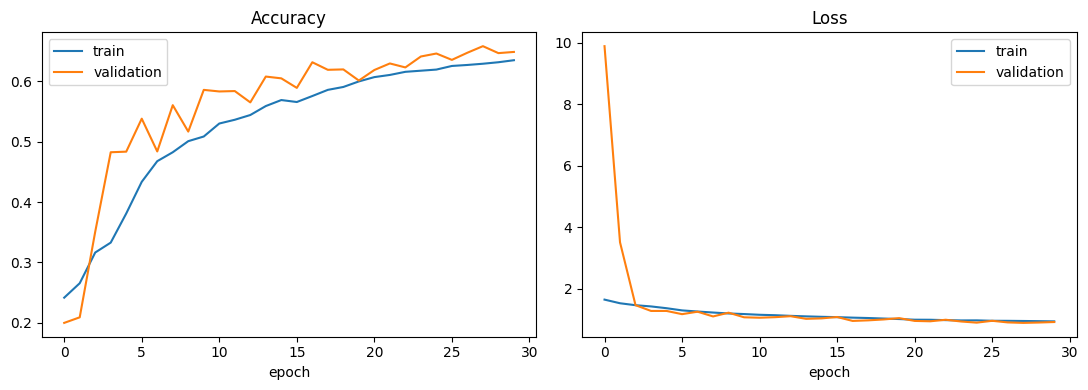


Test accuracy: 0.6710

              precision    recall  f1-score   support

       angry       0.57      0.54      0.55       491
       happy       0.84      0.81      0.83       879
     neutral       0.58      0.62      0.60       626
         sad       0.51      0.53      0.52       594
    surprise       0.82      0.80      0.81       416

    accuracy                           0.67      3006
   macro avg       0.66      0.66      0.66      3006
weighted avg       0.67      0.67      0.67      3006



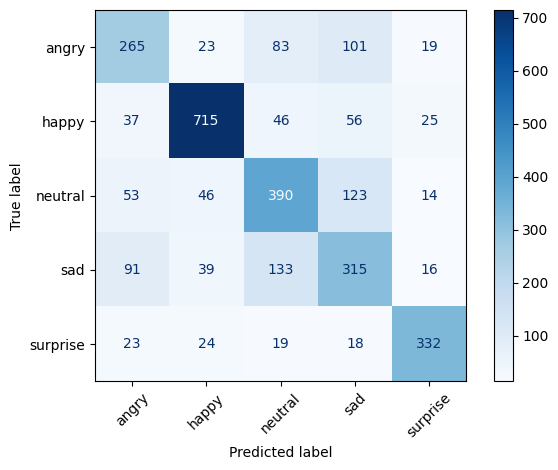

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

MOODS = ["angry", "happy", "neutral", "sad", "surprise"]
ID_MAP = {0: 0, 3: 1, 6: 2, 4: 3, 5: 4}

# 1) نمودار accuracy و loss
with open("history.json") as f:
    h = json.load(f)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(h["accuracy"], label="train")
ax[0].plot(h["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["loss"], label="train")
ax[1].plot(h["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

# 2) لود داده تست
df = pd.read_csv("fer2013.csv")
df = df[df["emotion"].isin(list(ID_MAP.keys()))]
df = df[df["Usage"] == "PrivateTest"].copy()
df["label"] = df["emotion"].map(ID_MAP).astype(int)
X_test = np.stack([np.array(p.split(), dtype="float32") for p in df["pixels"]])
X_test = X_test.reshape(-1, 48, 48, 1) / 255.0
y_test = df["label"].values

# 3) ارزیابی روی داده تست
model = tf.keras.models.load_model("best_model.keras")
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest accuracy: {acc:.4f}\n")

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, y_pred, target_names=MOODS))

# 4) Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=MOODS).plot(cmap="Blues", xticks_rotation=45)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

## ۵) تست روی عکس‌های خودم
تابع predict_mood خروجی رو به فرمت قرارداد می‌ده: {"mood": ..., "confidence": ...}. هر ۵ عکس درست تشخیص داده شد. فقط neutral اطمینان پایینی داشت (۰.۳۶).

found: ['me_angry.png', 'me_happy.png', 'me_natrual.png', 'me_sad.png', 'me_surprise.png']
me_angry.png -> {"mood": "angry", "confidence": 0.73}
me_happy.png -> {"mood": "happy", "confidence": 0.84}
me_natrual.png -> {"mood": "neutral", "confidence": 0.36}
me_sad.png -> {"mood": "sad", "confidence": 0.7}
me_surprise.png -> {"mood": "surprise", "confidence": 0.48}


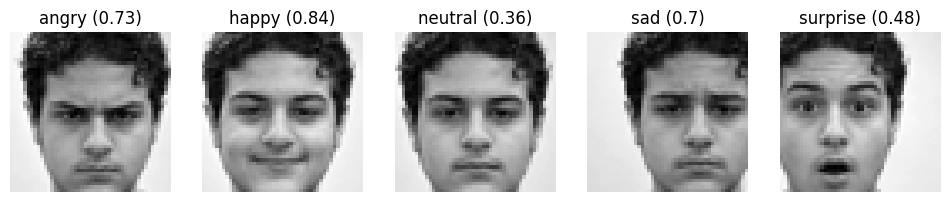

In [1]:
import glob
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

MOODS = ["angry", "happy", "neutral", "sad", "surprise"]
model = tf.keras.models.load_model("best_model.keras")

ROTATE = 90   # اگه صورت‌ها وارونه شدن، بذار 270 (یا 0 اگه درست بودن)
ZOOM = 0.6    # چند درصد وسط عکس نگه داشته بشه (۰.۵ تا ۰.۸)

def load_face(path):
    img = ImageOps.exif_transpose(Image.open(path)).convert("L")
    img = img.rotate(ROTATE, expand=True)
    w, h = img.size
    s = int(min(w, h) * ZOOM)
    cx, cy = w // 2, int(h * 0.45)   # کمی بالاتر از وسط، جای صورت
    box = (cx - s // 2, cy - s // 2, cx + s // 2, cy + s // 2)
    img = img.crop(box)
    img = ImageOps.autocontrast(img)
    return img.resize((48, 48))

def predict_mood(path):
    face = load_face(path)
    x = np.array(face, dtype="float32").reshape(1, 48, 48, 1) / 255.0
    probs = model.predict(x, verbose=0)[0]
    i = int(np.argmax(probs))
    return {"mood": MOODS[i], "confidence": round(float(probs[i]), 2)}, face

files = sorted(glob.glob("me_*.*"))
print("found:", files)

plt.figure(figsize=(12, 3))
for k, path in enumerate(files):
    result, face = predict_mood(path)
    print(path, "->", json.dumps(result))
    plt.subplot(1, len(files), k + 1)
    plt.imshow(face, cmap="gray")
    plt.title(f'{result["mood"]} ({result["confidence"]})')
    plt.axis("off")
plt.savefig("my_photos_test.png", dpi=150)
plt.show()

## جمع‌بندی
مدل به دقت ۶۷٪ روی تست رسید که برای یک CNN کوچک روی FER-2013 معمولیه. تصاویر کم‌کیفیت (48×48) و برچسب‌های نویزی دیتاست سقف دقت رو محدود می‌کنن. برای بهتر شدن می‌شه از data augmentation بیشتر یا یک مدل عمیق‌تر استفاده کرد.